# Stage 10: Counterfactuals
**Project:** Hospital Care Quality & Efficiency Analytics
**Data:** the validated mart, the cardiac risk scores from `02_readmission_model.ipynb`, and published effect sizes

**Question:** which programs would have brought the hospital's cardiac readmissions and bed occupancy back
within their goals over 2023 to 2025, and what is the most cost-effective way to do it?

**How the programs are judged**

| Priority | Goal | Standard it follows | Met if |
|---|---|---|---|
| **Primary 1** | Cardiac 30-day unplanned readmission rate, 2023 to 2025 | Three-year window, as in the Medicare readmission program | At or below the hospital's own best three-year rate |
| **Primary 2** | Daily network bed occupancy, 2023 to 2025 | 92% maximum (NHS planning guidance); 85% safe level reported as a warning | No day above 92% |
| Secondary | Cost | Cost per readmission avoided, return on investment and net savings | Among options that meet both primary goals, the lowest cost is preferred |

Quality programs are judged first on whether they achieve their clinical and capacity goals; cost then decides
between the options that do.

**The programs and their dials**

Each dial represents a program that hospitals already use, with its effect taken from published studies
(numbers in brackets refer to the References section).

| Program | Dial | Range | Evidence |
|---|---|---|---|
| Targeted transitional care (follow-up after discharge for high-risk patients) | Share of cardiac patients followed up, highest model risk first | 0% to 100% | Transitional Care Model trials [2, 3]; meta-analyses [4, 5] |
| Hospital-wide discharge program (every discharged patient) | Off or on | Off, on | Project RED randomized trial [1] |
| Outpatient (day-case) chemotherapy | Share of planned lung cancer stays given as day cases | 0% to 80% | Inpatient-to-outpatient chemotherapy transition [7] |
| Shorter withdrawal-management stays | Nights cut from each substance-use stay (at least 1 night kept) | 0 to 3 nights | Outpatient versus inpatient detoxification [8] |

**Method notes**
* Results are **expected values**: the notebook estimates how many readmissions would be avoided on average, not which patients.
* Readmissions avoided use the **actual readmissions** among the patients followed up, so the model's remaining overconfidence at the top of the risk scale does not inflate the results. The predicted risks are shown as a cross-check.
* Freed bed nights count as **capacity, not cash**: a freed bed only saves money if beds are closed or reused.
* Pathway implementation costs are not modelled, so between capacity settings the smallest change is the one that frees the fewest bed nights.
* Costs are Synthea's synthetic costs and are illustrative only.

| Part | Section | Question |
|---|---|---|
| | 1 to 3 | Where the hospital stands, assumptions, inputs |
| **A. Primary goals** | 4 | Cardiac follow-up: readmissions avoided at each level of coverage |
| | 5 | The capacity dials |
| | 6 | One dial at a time |
| | 7 | Which program packages meet the primary goals? |
| **B. Cost (secondary)** | 8 | Value for money of each package |
| | 9 | Net savings and break-even |
| | 10 | Targeted versus hospital-wide |
| | 11 | Save the results |
| | 12 | Summary |
| | 13 | References |

## 0. Setup

In [19]:
%matplotlib inline
import sys
from math import ceil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import text

# Find the project root (the folder containing .env) and import config.py from python/
root = Path.cwd()
while not (root / ".env").exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / "python"))
from config import get_engine

engine = get_engine()
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)


def q(sql):
    """Run a SQL query in PostgreSQL and return the (small) result as a DataFrame."""
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn)


def usd(x):
    return f"-${abs(x):,.0f}" if x < 0 else f"${x:,.0f}"


settings = q("""
    -- query: settings
    SELECT start_date, end_date, test_start_date, safe_occupancy, max_occupancy
    FROM mart.analysis_window
""").iloc[0]
TEST_START = pd.Timestamp(settings["test_start_date"])
TEST_END = pd.Timestamp(settings["end_date"])
SAFE, MAX = float(settings["safe_occupancy"]), float(settings["max_occupancy"])
print(f"Test period {TEST_START:%Y-%m-%d} to {TEST_END:%Y-%m-%d}, safe level {SAFE:.0%}, maximum {MAX:.0%}")

Test period 2023-01-01 to 2025-12-31, safe level 85%, maximum 92%


## 1. Where does the hospital stand today?
The cardiac target is the hospital's **own best three-year readmission rate** within 2017 to 2025. It is
calculated from the data rather than typed in, so it updates if the pipeline is ever rebuilt.

In [20]:
yearly = q("""
    -- query: yearly
    SELECT EXTRACT(YEAR FROM f.admit_date)::int        AS year,
           SUM(f.is_index_eligible)                    AS index_episodes,
           SUM(COALESCE(f.is_readmitted_30d, 0))       AS readmissions
    FROM mart.fact_episode f
    JOIN mart.dim_diagnosis d ON d.diagnosis_key = f.diagnosis_key
    WHERE d.diagnosis_group = 'Cardiac'
    GROUP BY 1
    ORDER BY 1
""")

windows = yearly.rolling(3).sum().dropna()
windows["window"] = [f"{y - 2}-{y}" for y in yearly["year"].iloc[2:]]
windows["rate_pct"] = 100 * windows["readmissions"] / windows["index_episodes"]
windows = windows[["window", "index_episodes", "readmissions", "rate_pct"]].reset_index(drop=True)

best = windows.loc[windows["rate_pct"].idxmin()]
TARGET_RATE = best["readmissions"] / best["index_episodes"]
print(f"Best three-year window: {best['window']} at {TARGET_RATE:.2%} (the target)")
windows.round(2)

Best three-year window: 2021-2023 at 6.45% (the target)


,window,index_episodes,readmissions,rate_pct
0,2017-2019,2048.0,181.0,8.84
1,2018-2020,2146.0,190.0,8.85
2,2019-2021,2195.0,176.0,8.02
3,2020-2022,2225.0,160.0,7.19
4,2021-2023,2264.0,146.0,6.45
5,2022-2024,2376.0,166.0,6.99
6,2023-2025,2504.0,187.0,7.47


**Interpretation:** The hospital's best three-year window was 2021 to 2023, at 6.45% (146 readmissions in 2,264 cardiac index episodes), so that is the target. The latest window, 2023 to 2025, sits at 7.47% (187 in 2,504), so the hospital **misses primary goal 1** today and needs about 25 to 26 fewer cardiac readmissions over three years to meet the goal. Rates were highest in 2017 to 2020 (around 8.8%), fell to their best in 2021 to 2023 and have been rising since. The two windows share 2023, because the data covers only nine years; that softens the contrast slightly but does not change the logic.

## 2. Assumptions and scenarios
Effect sizes and program costs come from published studies, with a **no-effect** stress test added.
The effect sizes drive the primary goals (Part A); the program costs are used only in Part B.
Each scenario pairs an effect with a cost so it tells one consistent story: the pessimistic case has a weak
effect and a high cost, the optimistic case a strong effect and a low cost.

| Assumption | Value | Source |
|---|---|---|
| Effect, low | 10% fewer readmissions | Meta-analysis of 25 nurse-led transitional care trials (8,422 heart failure patients): all-cause readmission RR 0.91 (95% CI 0.82 to 0.99) [5] |
| Effect, central | 30% fewer | Project RED randomized trial (738 patients): 30% less hospital use within 30 days of discharge [1] |
| Effect, high | 45% fewer | Transitional Care Model trial (363 high-risk older patients): rehospitalization 20.3% vs 37.1% over 24 weeks [2] |
| Program cost per patient | $519 to $1,160 (central $840) | Transitional Care Model, 2017 dollars [6] |
| Lung cancer day-case share | Up to 80% | 79% of eligible patients moved to outpatient treatment at one cancer center (goal 90%) [7] |
| Substance-use stay reduction | Up to about 2.5 nights | Outpatient alcohol detox averaged 6.5 days against 9 days inpatient, with similar outcomes [8] |

A wider review of heart failure transitional care found that home-visiting programs and multidisciplinary
heart failure clinics reduced all-cause readmission and mortality, while telemonitoring and education alone did not [4].

The effect sizes come mostly from older heart failure patients. This cohort also includes bypass and valve
patients, so the effect could differ; the range of scenarios covers that uncertainty.

In [21]:
SCENARIOS = {
    "No effect (stress test)": {"effect": 0.00, "cost": 840},
    "Pessimistic": {"effect": 0.10, "cost": 1160},
    "Central": {"effect": 0.30, "cost": 840},
    "Optimistic": {"effect": 0.45, "cost": 519},
}
EFFECTS_EVIDENCE = {"Low (10%)": 0.10, "Central (30%)": 0.30, "High (45%)": 0.45}
COSTS_EVIDENCE = {"Low ($519)": 519, "Central ($840)": 840, "High ($1,160)": 1160}

COVERAGES = np.round(np.arange(0, 1.0001, 0.05), 2)
LUNG_SHARES = np.round(np.arange(0, 0.80001, 0.10), 2)
SUBST_NIGHTS = [0, 1, 2, 3]          # 3 nights goes slightly beyond the evidence (about 2.5)
SUBST_EVIDENCE_MAX = 2.5

pd.DataFrame(SCENARIOS).T

,effect,cost
No effect (stress test),0.00,840.0
Pessimistic,0.10,1160.0
Central,0.30,840.0
Optimistic,0.45,519.0


## 3. Load the inputs
Four inputs, each checked against the validated pipeline:
* **Risk scores** for the 2,504 cardiac index episodes of 2023 to 2025, from the champion model
* **Index episodes** of 2023 to 2025 (all diagnoses), with the cost of each readmission
* **Daily network census** of 2023 to 2025 against the 90 sized beds
* **Bed nights** of lung cancer and substance-use stays in 2023 to 2025

In [22]:
scores = q("""
    -- query: scores
    SELECT episode_id, risk_score, risk_rank, readmitted, model
    FROM mart.cardiac_risk_scores
""")

index_eps = q("""
    -- query: index_episodes
    WITH seq AS (
        SELECT e.episode_id,
               LEAD(e.total_cost) OVER (PARTITION BY e.patient_id
                                        ORDER BY e.admit_ts, e.episode_id) AS next_cost
        FROM staging.episodes e
    )
    SELECT f.episode_id,
           d.diagnosis_group,
           COALESCE(f.is_readmitted_30d, 0)                          AS readmitted,
           CASE WHEN f.is_readmitted_30d = 1 THEN s.next_cost ELSE 0 END AS readmission_cost
    FROM mart.fact_episode f
    JOIN mart.dim_diagnosis d ON d.diagnosis_key = f.diagnosis_key
    JOIN seq s ON s.episode_id = f.episode_id
    CROSS JOIN mart.analysis_window w
    WHERE f.is_index_eligible = 1
      AND f.admit_date >= w.test_start_date
""")

census = q("""
    -- query: census
    SELECT census_date, patients_in_bed, beds
    FROM mart.fact_daily_occupancy
    WHERE is_test_period = 1
    ORDER BY census_date
""")

pathway_eps = q("""
    -- query: pathway_episodes
    SELECT e.episode_id, e.diagnosis_group, e.is_planned_treatment,
           e.admit_date, e.los_days
    FROM staging.episodes e
    CROSS JOIN mart.analysis_window w
    WHERE e.diagnosis_group IN ('Lung cancer', 'Substance use')
      AND e.admit_date + e.los_days - 1 >= w.test_start_date
      AND e.admit_date <= w.end_date
""")

# Cardiac follow-up inputs, ordered from highest to lowest risk
cardiac = (scores.merge(index_eps[["episode_id", "diagnosis_group", "readmission_cost"]],
                        on="episode_id", how="left")
                 .sort_values("risk_rank").reset_index(drop=True))
N_CARD, CARD_READMITS = len(cardiac), int(cardiac["readmitted"].sum())
N_ALL, ALL_READMITS = len(index_eps), int(index_eps["readmitted"].sum())
ALL_READMIT_COST = index_eps["readmission_cost"].sum()
BEDS = int(census["beds"].iloc[0])
BASE_CENSUS = census["patients_in_bed"].to_numpy(dtype=float)
N_DAYS = len(census)

# Consistency checks against the validated pipeline
assert N_CARD == 2504 and CARD_READMITS == 187, "Scores do not match the validated cardiac cohort"
assert cardiac["diagnosis_group"].eq("Cardiac").all(), "Some scored episodes are missing or not cardiac"
assert (index_eps["diagnosis_group"] == "Cardiac").sum() == N_CARD, "Cardiac index episodes do not match the scores"
assert N_DAYS == 1096 and BEDS == 90, "Census does not match the validated pipeline"
BASE_OVER_MAX = int((BASE_CENSUS / BEDS > MAX).sum())
BASE_OVER_SAFE = int((BASE_CENSUS / BEDS > SAFE).sum())
assert BASE_OVER_MAX == 7 and BASE_OVER_SAFE == 49, "Days over 92% / 85% do not match the golden numbers"

card_cost = cardiac.loc[cardiac["readmitted"] == 1, "readmission_cost"]
print(f"Cardiac index episodes: {N_CARD:,}, readmissions: {CARD_READMITS} ({CARD_READMITS / N_CARD:.2%})")
print(f"All index episodes:     {N_ALL:,}, readmissions: {ALL_READMITS} ({ALL_READMITS / N_ALL:.2%})")
print(f"Cardiac readmission cost: mean {usd(card_cost.mean())}, median {usd(card_cost.median())}, "
      f"total {usd(card_cost.sum())} over three years")
print(f"Census: {N_DAYS:,} days, {BEDS} beds, {BASE_OVER_SAFE} days over 85%, {BASE_OVER_MAX} days over 92%")

Cardiac index episodes: 2,504, readmissions: 187 (7.47%)
All index episodes:     12,960, readmissions: 237 (1.83%)
Cardiac readmission cost: mean $13,414, median $1,872, total $2,508,354 over three years
Census: 1,096 days, 90 beds, 49 days over 85%, 7 days over 92%


**Interpretation:** All inputs match the validated pipeline: 2,504 scored cardiac episodes with 187 readmissions, and a census of 1,096 days in which 49 days exceed 85% and **7 days exceed 92%, so the hospital also misses primary goal 2 today**. Across all diagnoses there are 12,960 index episodes and 237 readmissions, which is what a hospital-wide program would have to cover. Cardiac readmissions cost $2.5 million over three years, but the cost is extremely skewed: the average readmission costs $13,414 while the median costs only $1,872. A small number of very expensive readmissions carry most of the cost, so the savings from follow-up depend heavily on whether those particular patients are among the ones followed up.

In [23]:
# Turn each lung cancer and substance-use stay into one row per night spent in the test period
ep = pathway_eps.reset_index(drop=True)
nights = ep["los_days"].clip(lower=1).to_numpy()
row = np.repeat(np.arange(len(ep)), nights)
night_no = np.arange(nights.sum()) - np.repeat(np.cumsum(nights) - nights, nights)   # 0 = first night
night_date = pd.to_datetime(ep["admit_date"]).to_numpy()[row] + night_no.astype("timedelta64[D]")
day = ((night_date - np.datetime64(TEST_START)) // np.timedelta64(1, "D")).astype(int)
in_test = (day >= 0) & (day < N_DAYS)

is_lung = (ep["diagnosis_group"].eq("Lung cancer") & ep["is_planned_treatment"].astype(bool)).to_numpy()[row]
is_subst = ep["diagnosis_group"].eq("Substance use").to_numpy()[row]

# Planned lung cancer nights per day: a day-case share s removes s of these
LUNG_NIGHTS = np.bincount(day[in_test & is_lung], minlength=N_DAYS).astype(float)

# Substance-use nights removed per day when each stay is cut by d nights (at least 1 night kept):
# the last d nights of each stay are removed
stay_len = nights[row]
SUBST_CUT = {}
for d in SUBST_NIGHTS:
    removed = in_test & is_subst & (night_no >= np.maximum(1, stay_len - d))
    SUBST_CUT[d] = np.bincount(day[removed], minlength=N_DAYS).astype(float)

subst_census = np.bincount(day[in_test & is_subst], minlength=N_DAYS)
print(f"Planned lung cancer bed nights in 2023-2025: {LUNG_NIGHTS.sum():,.0f} "
      f"({LUNG_NIGHTS.sum() / BASE_CENSUS.sum():.1%} of all bed nights)")
print(f"Substance-use bed nights in 2023-2025:      {subst_census.sum():,.0f} "
      f"({subst_census.sum() / BASE_CENSUS.sum():.1%} of all bed nights)")
for d in SUBST_NIGHTS[1:]:
    print(f"  cutting {d} night(s) per stay frees {SUBST_CUT[d].sum():,.0f} bed nights")

Planned lung cancer bed nights in 2023-2025: 23,873 (34.2% of all bed nights)
Substance-use bed nights in 2023-2025:      24,944 (35.7% of all bed nights)
  cutting 1 night(s) per stay frees 2,909 bed nights
  cutting 2 night(s) per stay frees 5,417 bed nights
  cutting 3 night(s) per stay frees 7,580 bed nights


**Interpretation:** In 2023 to 2025, planned lung cancer treatment fills 23,873 bed nights (34.2% of all bed nights) and substance-use stays fill 24,944 (35.7%). Together they occupy about 70% of the network's beds, even more than the 62% seen across the full 2017 to 2025 window, which confirms the bed bottleneck sits with these two groups. Cutting substance-use stays by one night frees 2,909 bed nights, two nights 5,417 and three nights 7,580; the gains shrink with each extra night because short stays are protected by the one-night minimum.

# Part A: Primary goals

## 4. Cardiac follow-up: readmissions avoided at each level of coverage
Follow-up goes to the highest-risk cardiac patients first. For each coverage level and scenario:
* **Readmissions avoided** = effect x the actual readmissions among the patients followed up
* **Number needed to treat (NNT)** = patients followed up for each readmission avoided (lower is better)
* **Primary goal 1** is met when the cardiac readmission rate falls to the target or below

The function also calculates the cost measures used later in Part B.

In [24]:
cum_readmits = np.concatenate([[0], np.cumsum(cardiac["readmitted"].to_numpy())])
cum_cost = np.concatenate([[0], np.cumsum(cardiac["readmission_cost"].to_numpy())])
cum_pred = np.concatenate([[0], np.cumsum(cardiac["risk_score"].to_numpy())])


def followup(scenario, coverage=0.0, hospital_wide=False):
    """Expected results of cardiac follow-up at one coverage level, or of hospital-wide follow-up."""
    effect, cost_pp = scenario["effect"], scenario["cost"]
    if hospital_wide:
        patients = N_ALL
        avoided_cardiac = effect * CARD_READMITS
        avoided_total = effect * ALL_READMITS
        savings = effect * ALL_READMIT_COST
    else:
        patients = ceil(coverage * N_CARD)
        avoided_cardiac = avoided_total = effect * cum_readmits[patients]
        savings = effect * cum_cost[patients]
    program_cost = patients * cost_pp
    rate = (CARD_READMITS - avoided_cardiac) / N_CARD
    net = savings - program_cost
    return {"patients": patients, "readmissions_avoided": avoided_total,
            "cardiac_rate_pct": 100 * rate,
            "nnt": patients / avoided_total if avoided_total > 0 else np.nan,
            "savings": savings, "program_cost": program_cost, "net_savings": net,
            "cost_per_readmission_avoided": program_cost / avoided_total if avoided_total > 0 else np.nan,
            "roi_pct": 100 * net / program_cost if program_cost > 0 else np.nan,
            "goal_1_met": rate <= TARGET_RATE + 1e-12, "breaks_even": net >= 0}


rows = []
for name, scen in SCENARIOS.items():
    for cov in COVERAGES:
        rows.append({"scenario": name, "coverage": cov, "hospital_wide": False, **followup(scen, cov)})
    rows.append({"scenario": name, "coverage": 1.0, "hospital_wide": True, **followup(scen, hospital_wide=True)})
fu = pd.DataFrame(rows)

central = fu[(fu["scenario"] == "Central") & ~fu["hospital_wide"]]
(central[central["coverage"].isin([0.05, 0.10, 0.20, 0.30, 0.50, 1.0])]
 [["coverage", "patients", "readmissions_avoided", "cardiac_rate_pct", "nnt", "goal_1_met"]].round(2))

,coverage,patients,readmissions_avoided,cardiac_rate_pct,nnt,goal_1_met
45,0.05,126,6.3,7.22,20.00,False
46,0.10,251,9.6,7.08,26.15,False
48,0.20,501,18.9,6.71,26.51,False
50,0.30,752,26.4,6.41,28.48,True
54,0.50,1252,41.4,5.81,30.24,True
64,1.00,2504,56.1,5.23,44.63,True


**Interpretation:** In the central scenario, following up the riskiest 5% of cardiac patients avoids about 6 readmissions over three years, with one avoided for every 20 patients followed up (NNT 20). The riskiest 10% avoids about 10 (NNT 26) and brings the rate to 7.08%, still above the 6.45% target. **Goal 1 is first met at the riskiest 30%**: 752 patients, about 26 readmissions avoided, a rate of 6.41% and an NNT of 28.5. Widening further keeps lowering the rate, to 5.23% with every cardiac patient, but the NNT climbs to about 45, because each extra patient is less likely to be readmitted than the last. That rising NNT is why targeting the highest-risk patients first matters.

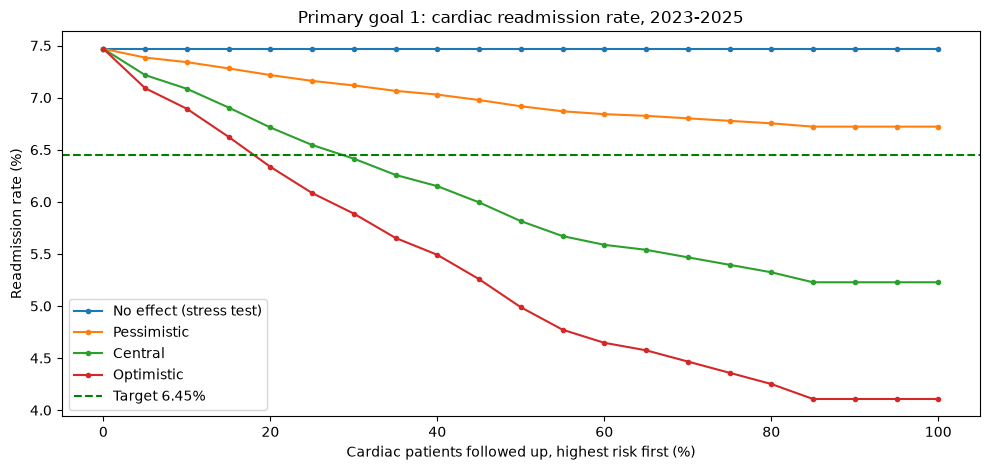

,smallest_coverage_meeting_goal_1,patients,readmissions_avoided,cardiac_rate_pct,nnt
scenario,,,,,
No effect (stress test),None,NaN,NaN,NaN,NaN
Pessimistic,None,NaN,NaN,NaN,NaN
Central,30%,752.0,26.40,6.41,28.48
Optimistic,20%,501.0,28.35,6.34,17.67


In [25]:
fig, ax = plt.subplots(figsize=(10, 4.8))
for name in SCENARIOS:
    d = fu[(fu["scenario"] == name) & ~fu["hospital_wide"]]
    ax.plot(100 * d["coverage"], d["cardiac_rate_pct"], marker=".", label=name)
ax.axhline(100 * TARGET_RATE, color="green", ls="--", label=f"Target {TARGET_RATE:.2%}")
ax.set_title("Primary goal 1: cardiac readmission rate, 2023-2025")
ax.set_xlabel("Cardiac patients followed up, highest risk first (%)"); ax.set_ylabel("Readmission rate (%)")
ax.legend()
plt.tight_layout(); plt.show()

# Smallest coverage that meets goal 1 in each scenario
reach = []
for name in SCENARIOS:
    d = fu[(fu["scenario"] == name) & ~fu["hospital_wide"] & fu["goal_1_met"]].sort_values("coverage")
    r = d.iloc[0] if len(d) else None
    reach.append({"scenario": name,
                  "smallest_coverage_meeting_goal_1": None if r is None else f"{r['coverage']:.0%}",
                  "patients": np.nan if r is None else r["patients"],
                  "readmissions_avoided": np.nan if r is None else r["readmissions_avoided"],
                  "cardiac_rate_pct": np.nan if r is None else r["cardiac_rate_pct"],
                  "nnt": np.nan if r is None else r["nnt"]})
pd.DataFrame(reach).set_index("scenario").round(2)

**Interpretation:** How much coverage goal 1 needs depends on how well follow-up works. Under central assumptions it is the riskiest **30%** (752 patients, NNT 28.5); under optimistic assumptions the riskiest **20%** is enough (501 patients, a rate of 6.34% and NNT 17.7). Under pessimistic assumptions the target is out of reach: even following up every cardiac patient only brings the rate to about 6.72%. With no effect, the rate stays at 7.47%. The readmission goal is achievable, but only if follow-up delivers at least the central effect from the published trials.

In [26]:
# Cross-check: readmissions avoided using the model's predicted risk instead of actual outcomes (central effect)
check = pd.DataFrame({"coverage": [0.05, 0.10, 0.20, 0.30, 0.50]})
check["patients"] = [ceil(c * N_CARD) for c in check["coverage"]]
check["actual_readmissions_in_group"] = [cum_readmits[k] for k in check["patients"]]
check["predicted_readmissions_in_group"] = [cum_pred[k] for k in check["patients"]]
check["avoided_actual_basis"] = 0.30 * check["actual_readmissions_in_group"]
check["avoided_predicted_basis"] = 0.30 * check["predicted_readmissions_in_group"]
check["coverage"] = check["coverage"].map("{:.0%}".format)
check.round(1)

,coverage,patients,actual_readmissions_in_group,predicted_readmissions_in_group,avoided_actual_basis,avoided_predicted_basis
0,5%,126,21,24.8,6.3,7.4
1,10%,251,32,41.0,9.6,12.3
2,20%,501,63,68.1,18.9,20.4
3,30%,752,88,91.6,26.4,27.5
4,50%,1252,138,131.3,41.4,39.4


**Interpretation:** The model's predicted risks overstate readmissions among the very highest-risk patients (41 predicted against 32 actual in the riskiest 10%), and the gap closes by 30 to 50% coverage. This is the overconfidence at the top of the risk scale found in the model notebook. Because the counterfactuals use the **actual** readmissions, the estimates of readmissions avoided are slightly more conservative than the predicted risks would suggest, so the savings shown are not inflated by the model.

## 5. The capacity dials
Primary goal 2 depends only on the two pathway dials. The heatmap shows the number of days above 92% occupancy in
2023 to 2025 for every combination; a cell with **0** meets the goal. Days above 85% are reported as a warning.

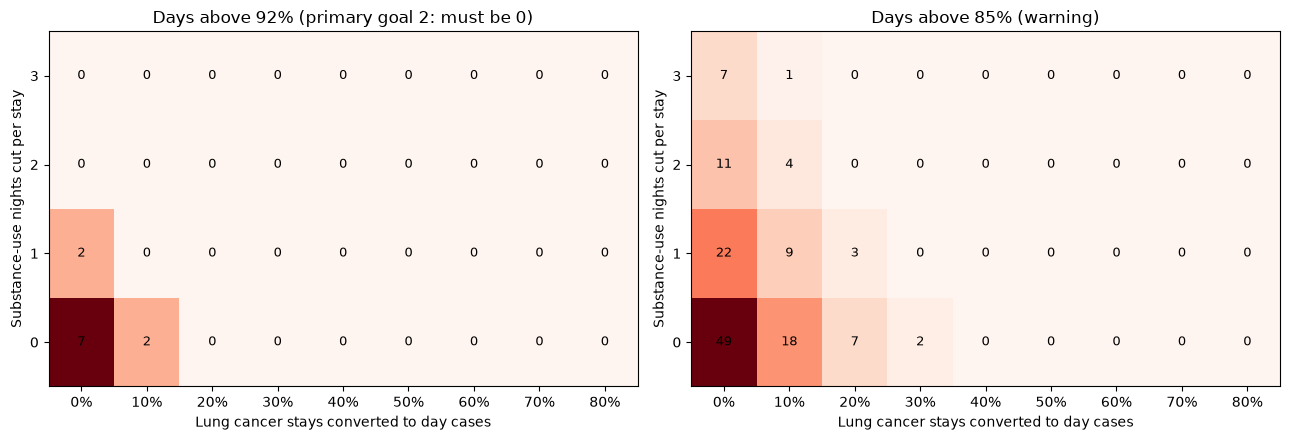

In [27]:
def capacity(lung_share=0.0, subst_nights=0):
    """Daily occupancy after converting a share of lung cancer stays to day cases and shortening substance-use stays."""
    new_census = BASE_CENSUS - lung_share * LUNG_NIGHTS - SUBST_CUT[subst_nights]
    occ = new_census / BEDS
    return {"days_over_92": int((occ > MAX).sum()), "days_over_85": int((occ > SAFE).sum()),
            "bed_nights_freed": float(BASE_CENSUS.sum() - new_census.sum()),
            "avg_occupancy_pct": 100 * occ.mean(), "peak_occupancy_pct": 100 * occ.max(),
            "goal_2_met": int((occ > MAX).sum()) == 0}


cap = pd.DataFrame([{"lung_share": s, "subst_nights": d, **capacity(s, d)}
                    for s in LUNG_SHARES for d in SUBST_NIGHTS])
cap["dials_moved"] = (cap["lung_share"] > 0).astype(int) + (cap["subst_nights"] > 0).astype(int)
cap["beyond_evidence"] = cap["subst_nights"] > SUBST_EVIDENCE_MAX

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, metric, title in [(axes[0], "days_over_92", "Days above 92% (primary goal 2: must be 0)"),
                          (axes[1], "days_over_85", "Days above 85% (warning)")]:
    grid = cap.pivot(index="subst_nights", columns="lung_share", values=metric)
    im = ax.imshow(grid.values, cmap="Reds", aspect="auto", origin="lower")
    for (i, j), v in np.ndenumerate(grid.values):
        ax.text(j, i, int(v), ha="center", va="center", fontsize=9)
    ax.set_xticks(range(len(grid.columns)), [f"{c:.0%}" for c in grid.columns])
    ax.set_yticks(range(len(grid.index)), grid.index)
    ax.set_xlabel("Lung cancer stays converted to day cases"); ax.set_ylabel("Substance-use nights cut per stay")
    ax.set_title(title)
plt.tight_layout(); plt.show()

**Interpretation:** Primary goal 2 is easy to meet. Converting just **20% of planned lung cancer stays to day cases** removes every day above 92%, and so does cutting substance-use stays by 2 nights on its own; 10% day cases combined with a 1-night cut also works. The 85% warning line needs a little more: 40% day cases on their own bring days above 85% to zero, while the substance-use pathway alone still leaves 7 to 11 such days. Every combination that meets the goal sits well within the evidence (up to 80% day cases and about 2.5 nights).

## 6. One dial at a time
Starting from no change, each dial is moved on its own (central scenario for follow-up), to show how every
primary metric responds to each variable separately.

In [28]:
base_fu = followup(SCENARIOS["Central"])
base_cap = capacity()
moves = [
    ("Follow-up: riskiest 10% of cardiac patients", {"coverage": 0.10}, {}),
    ("Follow-up: riskiest 30% of cardiac patients", {"coverage": 0.30}, {}),
    ("Follow-up: all cardiac patients", {"coverage": 1.0}, {}),
    ("Follow-up: hospital-wide (every patient)", {"hospital_wide": True}, {}),
    ("Lung cancer: 40% day cases", {}, {"lung_share": 0.40}),
    ("Lung cancer: 80% day cases", {}, {"lung_share": 0.80}),
    ("Substance use: 2 nights shorter", {}, {"subst_nights": 2}),
]
one = [{"change": "No change", "cardiac_rate_pct": base_fu["cardiac_rate_pct"],
        "readmissions_avoided": 0.0, "days_over_92": base_cap["days_over_92"],
        "days_over_85": base_cap["days_over_85"], "bed_nights_freed": 0.0}]
for label, fu_args, cap_args in moves:
    f = followup(SCENARIOS["Central"], **fu_args) if fu_args else base_fu
    c = capacity(**cap_args) if cap_args else base_cap
    one.append({"change": label, "cardiac_rate_pct": f["cardiac_rate_pct"],
                "readmissions_avoided": f["readmissions_avoided"],
                "days_over_92": c["days_over_92"], "days_over_85": c["days_over_85"],
                "bed_nights_freed": c["bed_nights_freed"]})
one = pd.DataFrame(one).set_index("change")
one["goal_1_met"] = one["cardiac_rate_pct"] <= 100 * TARGET_RATE
one["goal_2_met"] = one["days_over_92"] == 0
one["beds_worth_freed"] = one["bed_nights_freed"] / N_DAYS
one.round(2)

,cardiac_rate_pct,readmissions_avoided,days_over_92,days_over_85,bed_nights_freed,goal_1_met,goal_2_met,beds_worth_freed
change,,,,,,,,
No change,7.47,0.0,7,49,0.0,False,False,0.00
Follow-up: riskiest 10% of cardiac patients,7.08,9.6,7,49,0.0,False,False,0.00
Follow-up: riskiest 30% of cardiac patients,6.41,26.4,7,49,0.0,True,False,0.00
Follow-up: all cardiac patients,5.23,56.1,7,49,0.0,True,False,0.00
Follow-up: hospital-wide (every patient),5.23,71.1,7,49,0.0,True,False,0.00
Lung cancer: 40% day cases,7.47,0.0,0,0,9549.2,False,True,8.71
Lung cancer: 80% day cases,7.47,0.0,0,0,19098.4,False,True,17.43
Substance use: 2 nights shorter,7.47,0.0,0,11,5417.0,False,True,4.94


**Interpretation:** Each dial moves only its own goal, which is why the hospital needs two separate fixes. Follow-up changes the readmission rate but leaves occupancy untouched, and the pathways do the opposite. On the readmission side, the riskiest 10% falls short (7.08%), while the riskiest 30% meets the goal (6.41%, about 26 readmissions avoided). Hospital-wide follow-up avoids the most readmissions in total (about 71), but brings the cardiac rate no lower than following up every cardiac patient (5.23%). On the capacity side, 40% lung cancer day cases clear both the 92% and 85% lines and free about 9,500 bed nights, the equivalent of **8.7 beds** on an average night; 80% frees about 17 beds' worth. Cutting substance-use stays by 2 nights clears the 92% line and frees about 5 beds' worth, but leaves 11 days above 85%. No single dial meets both goals.

## 7. Which program packages meet the primary goals?
Four packages, each built from programs in the literature. Settings are fixed by rules rather than picked from
the results, and all three packages with bed pathways use the same pathway settings, so they differ only in how
follow-up is delivered.

| Package | Follow-up | Bed pathways | Literature basis |
|---|---|---|---|
| Do nothing | None | None | Today's position |
| Bed pathways only | None | The smallest change that meets goal 2 | Outpatient chemotherapy [7] and shorter withdrawal-management stays [8] |
| **Targeted follow-up + bed pathways** (recommended) | Transitional care for the riskiest cardiac patients, at the smallest coverage that meets goal 1 in the central scenario | Same | Transitional Care Model, which enrolled high-risk older patients [2, 3] |
| Hospital-wide follow-up + bed pathways | A discharge program for every discharged patient | Same | Project RED, which enrolled general medical patients rather than a high-risk group [1] |

**Beds' worth freed** is the bed nights freed divided by the number of days, which is the number of beds the
change releases on an average night.

In [29]:
# Targeted follow-up: the smallest coverage that meets goal 1 in the central scenario
meets_1 = fu[(fu["scenario"] == "Central") & ~fu["hospital_wide"] & fu["goal_1_met"]].sort_values("coverage")
recommended_coverage = float(meets_1.iloc[0]["coverage"]) if len(meets_1) else 1.0

# Bed pathways: the setting that meets goal 2 while freeing the fewest bed nights
meets_2 = cap[cap["goal_2_met"]].sort_values(["bed_nights_freed", "dials_moved"])
PATHWAYS = ({"lung_share": float(meets_2.iloc[0]["lung_share"]), "subst_nights": int(meets_2.iloc[0]["subst_nights"])}
            if len(meets_2) else {"lung_share": 0.40, "subst_nights": 2})

RECOMMENDED = "Targeted follow-up + bed pathways"
OPTIONS = {
    "Do nothing": {"coverage": 0.0, "hospital_wide": False, "lung_share": 0.0, "subst_nights": 0},
    "Bed pathways only": {"coverage": 0.0, "hospital_wide": False, **PATHWAYS},
    RECOMMENDED: {"coverage": recommended_coverage, "hospital_wide": False, **PATHWAYS},
    "Hospital-wide follow-up + bed pathways": {"coverage": 1.0, "hospital_wide": True, **PATHWAYS},
}
BASIS = {
    "Do nothing": "Current practice",
    "Bed pathways only": "Outpatient chemotherapy [7]; shorter withdrawal-management stays [8]",
    RECOMMENDED: "Transitional Care Model [2, 3]; bed pathways [7, 8]",
    "Hospital-wide follow-up + bed pathways": "Project RED [1]; bed pathways [7, 8]",
}

rows = []
for option, s in OPTIONS.items():
    c = capacity(s["lung_share"], s["subst_nights"])
    for scen_name, scen in SCENARIOS.items():
        f = followup(scen, s["coverage"], s["hospital_wide"])
        rows.append({
            "option": option, "scenario": scen_name, "literature_basis": BASIS[option],
            "is_recommended": option == RECOMMENDED,
            "follow_up": "Hospital-wide" if s["hospital_wide"] else
                         ("None" if s["coverage"] == 0 else f"Riskiest {s['coverage']:.0%}"),
            "lung_day_case_share": s["lung_share"], "subst_nights_cut": s["subst_nights"],
            "patients_followed_up": f["patients"],
            # primary goals
            "cardiac_rate_pct": f["cardiac_rate_pct"], "readmissions_avoided": f["readmissions_avoided"],
            "nnt": f["nnt"], "days_over_92": c["days_over_92"], "days_over_85": c["days_over_85"],
            "bed_nights_freed": c["bed_nights_freed"], "beds_worth_freed": c["bed_nights_freed"] / N_DAYS,
            "goal_1_met": f["goal_1_met"], "goal_2_met": c["goal_2_met"],
            # secondary: cost
            "program_cost": f["program_cost"],
            "cost_per_readmission_avoided": f["cost_per_readmission_avoided"],
            "roi_pct": f["roi_pct"], "net_savings": f["net_savings"], "breaks_even": f["breaks_even"],
        })
options = pd.DataFrame(rows)
options["primary_goals"] = np.where(options["goal_1_met"] & options["goal_2_met"], "MET", "NOT MET")

print(f"Targeted follow-up: riskiest {recommended_coverage:.0%} of cardiac patients")
print(f"Bed pathways:       {PATHWAYS['lung_share']:.0%} lung cancer day cases, "
      f"{PATHWAYS['subst_nights']} night(s) cut from substance-use stays")
options.pivot(index="option", columns="scenario", values="primary_goals").loc[list(OPTIONS), list(SCENARIOS)]

Targeted follow-up: riskiest 30% of cardiac patients
Bed pathways:       20% lung cancer day cases, 0 night(s) cut from substance-use stays


scenario,No effect (stress test),Pessimistic,Central,Optimistic
option,,,,
Do nothing,NOT MET,NOT MET,NOT MET,NOT MET
Bed pathways only,NOT MET,NOT MET,NOT MET,NOT MET
Targeted follow-up + bed pathways,NOT MET,NOT MET,MET,MET
Hospital-wide follow-up + bed pathways,NOT MET,NOT MET,MET,MET


**Interpretation:** Two packages meet both primary goals, under central and optimistic assumptions: **targeted follow-up + bed pathways** (transitional care for the riskiest 30% of cardiac patients, plus 20% of lung cancer treatment as day cases) and **hospital-wide follow-up + bed pathways**. **Bed pathways only** meets the capacity goal in every scenario but leaves the cardiac rate at 7.47%, so it never meets both. Under pessimistic or no-effect assumptions nothing meets the readmission goal, because the target is out of reach when follow-up reduces readmissions by 10% or less. The hospital needs both a follow-up program and the bed pathways.

In [30]:
# Primary scorecard for one scenario (change the scenario name to see another)
SHOW = "Central"
card = options[options["scenario"] == SHOW].set_index("option").loc[list(OPTIONS)]
pd.DataFrame({
    "follow_up": card["follow_up"],
    "1. cardiac rate": [f"{r:.2f}% {'MET' if p else 'NOT MET'}" for r, p in zip(card["cardiac_rate_pct"], card["goal_1_met"])],
    "2. days > 92%": [f"{d} {'MET' if p else 'NOT MET'}" for d, p in zip(card["days_over_92"], card["goal_2_met"])],
    "readmissions avoided": card["readmissions_avoided"].round(1),
    "NNT": card["nnt"].round(1),
    "days > 85%": card["days_over_85"],
    "beds' worth freed": card["beds_worth_freed"].round(1),
    "primary goals": card["primary_goals"],
})

,follow_up,1. cardiac rate,2. days > 92%,readmissions avoided,NNT,days > 85%,beds' worth freed,primary goals
option,,,,,,,,
Do nothing,None,7.47% NOT MET,7 NOT MET,0.0,NaN,49,0.0,NOT MET
Bed pathways only,None,7.47% NOT MET,0 MET,0.0,NaN,7,4.4,NOT MET
Targeted follow-up + bed pathways,Riskiest 30%,6.41% MET,0 MET,26.4,28.5,7,4.4,MET
Hospital-wide follow-up + bed pathways,Hospital-wide,5.23% MET,0 MET,71.1,182.3,7,4.4,MET


**Interpretation:** Under central assumptions, targeted follow-up brings the cardiac rate to 6.41% and avoids about 26 readmissions, with one readmission avoided for every 28.5 patients followed up (NNT). Hospital-wide follow-up goes further on readmissions (5.23%, about 71 avoided), but needs **182 patients followed up for each readmission avoided**, more than six times as many, because most of the patients it covers were never at high risk. All three packages with bed pathways remove every day above 92% and free about 4.4 beds' worth of capacity, but leave 7 days above the 85% safe level. Section 6 showed that raising the day-case share to 40% removes those warning days as well, freeing about 8.7 beds' worth, so a hospital could go further on the pathways at no extra follow-up cost.

# Part B: Cost (secondary)

## 8. Value for money of each package
Cost decides between packages that meet the primary goals. Three measures:
* **Cost per readmission avoided** = program cost / readmissions avoided, the standard cost-effectiveness ratio
* **Return on investment** = net savings / program cost
* **Net savings** = the cost of readmissions avoided minus the program cost, over three years

In [31]:
cost_card = options[options["scenario"] == SHOW].set_index("option").loc[list(OPTIONS)]
pd.DataFrame({
    "follow_up": cost_card["follow_up"],
    "primary goals": cost_card["primary_goals"],
    "program cost": cost_card["program_cost"].map(usd),
    "cost per readmission avoided": cost_card["cost_per_readmission_avoided"].map(
        lambda v: "n/a" if pd.isna(v) else usd(v)),
    "return on investment": cost_card["roi_pct"].map(lambda v: "n/a" if pd.isna(v) else f"{v:+.0f}%"),
    "net savings": cost_card["net_savings"].map(usd),
})

,follow_up,primary goals,program cost,cost per readmission avoided,return on investment,net savings
option,,,,,,
Do nothing,None,NOT MET,$0,n/a,n/a,$0
Bed pathways only,None,NOT MET,$0,n/a,n/a,$0
Targeted follow-up + bed pathways,Riskiest 30%,MET,"$631,680","$23,927",-43%,"-$269,839"
Hospital-wide follow-up + bed pathways,Hospital-wide,MET,"$10,886,400","$153,114",-92%,"-$9,972,421"


**Interpretation:** Of the two packages that meet both primary goals, targeted follow-up is by far the cheaper: **$631,680 against $10.9 million**, and **$23,927 per readmission avoided against $153,114** for hospital-wide follow-up, about six times less. Under central assumptions neither pays for itself in cash: targeted follow-up returns -43% (a net cost of about $270,000 over three years) and hospital-wide follow-up -92% (about $10 million). Bed pathways only shows no cost because pathway implementation costs are not modelled, and its freed beds are counted as capacity rather than cash. On the outcome-first rule, **targeted follow-up + bed pathways is the recommended package**: it is the cheapest way to meet both goals.

In [32]:
# Cost per readmission avoided in every scenario
(options.pivot(index="option", columns="scenario", values="cost_per_readmission_avoided")
        .loc[list(OPTIONS), list(SCENARIOS)].round(0))

scenario,No effect (stress test),Pessimistic,Central,Optimistic
option,,,,
Do nothing,NaN,NaN,NaN,NaN
Bed pathways only,NaN,NaN,NaN,NaN
Targeted follow-up + bed pathways,NaN,99127.0,23927.0,9856.0
Hospital-wide follow-up + bed pathways,NaN,634329.0,153114.0,63068.0


**Interpretation:** The cost per readmission avoided depends heavily on how well follow-up works. For targeted follow-up it ranges from **$9,856** under optimistic assumptions to $23,927 central and $99,127 pessimistic; with no effect nothing is avoided, so the ratio cannot be calculated. Hospital-wide follow-up costs about six times as much per readmission avoided in every scenario, from $63,068 to $634,329. The packages without follow-up avoid no readmissions, so they have no ratio. Because the value of the program rests so much on its real effect, a pilot should measure that effect early, before the program is scaled up.

## 9. Net savings and break-even
Cost is secondary, but it is still useful to know whether follow-up could pay for itself. The chart shows net
savings at every level of coverage, and the next one turns the question around: how large would the effect have to be to reach the
readmission target and to break even?

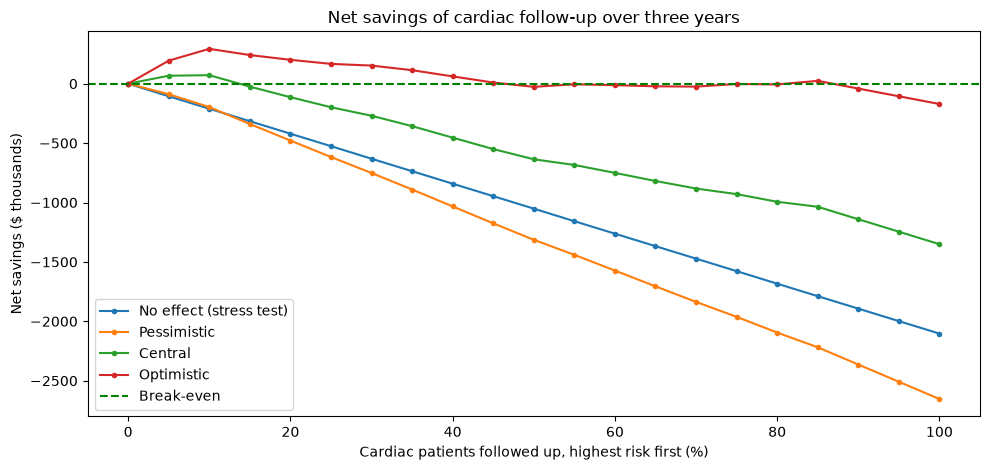

In [33]:
fig, ax = plt.subplots(figsize=(10, 4.8))
for name in SCENARIOS:
    d = fu[(fu["scenario"] == name) & ~fu["hospital_wide"]]
    ax.plot(100 * d["coverage"], d["net_savings"] / 1e3, marker=".", label=name)
ax.axhline(0, color="green", ls="--", label="Break-even")
ax.set_title("Net savings of cardiac follow-up over three years")
ax.set_xlabel("Cardiac patients followed up, highest risk first (%)"); ax.set_ylabel("Net savings ($ thousands)")
ax.legend()
plt.tight_layout(); plt.show()

**Interpretation:** Net savings are positive only at narrow coverage. In the central scenario they peak at about $72,000 around the riskiest 10% and turn negative by about 15%; the optimistic scenario stays positive up to about 45%. The pessimistic and no-effect scenarios lose money at every level. The Recommended package's 30% coverage therefore costs more than it saves under central assumptions, but saves money under optimistic ones. Savings are also uneven because readmission costs are very skewed (an average of $13,414 against a median of $1,872): a few expensive readmissions carry most of the potential savings.

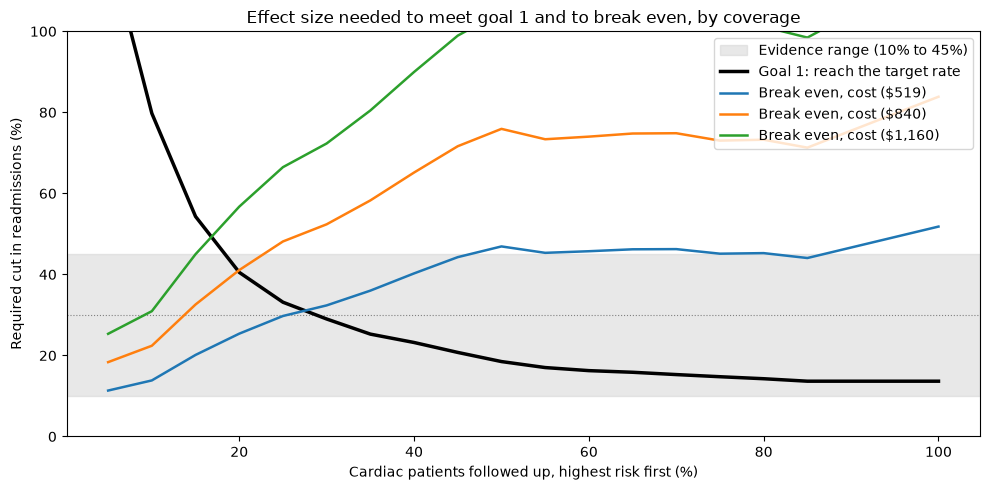

Readmissions to avoid for goal 1: 25.5 of 187


,coverage,patients,caught,effect_for_goal_1,effect_to_break_even_Low ($519),effect_to_break_even_Central ($840),"effect_to_break_even_High ($1,160)"
0,0.05,126,21,1.215,0.113,0.184,0.253
1,0.10,251,32,0.798,0.138,0.224,0.309
3,0.20,501,63,0.405,0.254,0.411,0.567
5,0.30,752,88,0.290,0.324,0.524,0.723
7,0.40,1002,110,0.232,0.403,0.651,0.900
9,0.50,1252,138,0.185,0.469,0.759,1.049
13,0.70,1753,167,0.153,0.462,0.749,1.034
19,1.00,2504,187,0.136,0.518,0.839,1.158


In [34]:
needed_avoided = CARD_READMITS - TARGET_RATE * N_CARD
req = pd.DataFrame({"coverage": COVERAGES[1:]})
req["patients"] = [ceil(c * N_CARD) for c in req["coverage"]]
req["caught"] = [cum_readmits[k] for k in req["patients"]]
req["effect_for_goal_1"] = needed_avoided / req["caught"]
for label, cost_pp in COSTS_EVIDENCE.items():
    req[f"effect_to_break_even_{label}"] = req["patients"] * cost_pp / [cum_cost[k] for k in req["patients"]]

fig, ax = plt.subplots(figsize=(10, 5))
ax.axhspan(10, 45, color="lightgrey", alpha=0.5, label="Evidence range (10% to 45%)")
ax.axhline(30, color="grey", lw=0.8, ls=":")
ax.plot(100 * req["coverage"], 100 * req["effect_for_goal_1"], color="black", lw=2.5,
        label="Goal 1: reach the target rate")
for label in COSTS_EVIDENCE:
    ax.plot(100 * req["coverage"], 100 * req[f"effect_to_break_even_{label}"], lw=1.8,
            label=f"Break even, cost {label.split(' ')[1]}")
ax.set_ylim(0, 100)
ax.set_title("Effect size needed to meet goal 1 and to break even, by coverage")
ax.set_xlabel("Cardiac patients followed up, highest risk first (%)")
ax.set_ylabel("Required cut in readmissions (%)")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

print(f"Readmissions to avoid for goal 1: {needed_avoided:.1f} of {CARD_READMITS}")
req[["coverage", "patients", "caught", "effect_for_goal_1"] +
    [c for c in req.columns if c.startswith("effect_to_break_even")]].iloc[[0, 1, 3, 5, 7, 9, 13, 19]].round(3)

**Interpretation:** This chart turns the question around. The black line is the effect needed to reach the readmission target (goal 1); it falls as coverage widens. The coloured lines are the effects needed to break even at each cost; they rise as coverage widens. Follow-up both meets goal 1 and pays for itself only above both lines, so the crossing points show the minimum effect needed:
* At **$519** per patient, the lines cross at about 25 to 30% coverage with an effect of about **31%**, just above the central estimate.
* At **$840**, they cross at about 20% coverage with an effect of about **41%**, near the top of the evidence range.
* At **$1,160**, they cross at about 15 to 20% coverage with an effect above 45%, outside the evidence.

So follow-up can meet the readmission goal and pay for itself only if it is **both cheap and highly effective**. Under central assumptions it meets the goal at a net cost, which is the trade-off the outcome-first rule accepts.

## 10. Targeted versus hospital-wide
The cheapest targeted program that meets goal 1, against hospital-wide follow-up, in every scenario.

In [35]:
comp = []
for name in SCENARIOS:
    d = fu[fu["scenario"] == name]
    targeted = d[~d["hospital_wide"] & d["goal_1_met"]].sort_values("program_cost")
    hw = d[d["hospital_wide"]].iloc[0]
    t = targeted.iloc[0] if len(targeted) else None
    comp.append({
        "scenario": name,
        "targeted_coverage": None if t is None else f"{t['coverage']:.0%}",
        "targeted_patients": np.nan if t is None else t["patients"],
        "targeted_cost": np.nan if t is None else t["program_cost"],
        "targeted_cost_per_readmission_avoided": np.nan if t is None else t["cost_per_readmission_avoided"],
        "targeted_nnt": np.nan if t is None else t["nnt"],
        "targeted_net_savings": np.nan if t is None else t["net_savings"],
        "hospital_wide_patients": hw["patients"],
        "hospital_wide_cost": hw["program_cost"],
        "hospital_wide_cost_per_readmission_avoided": hw["cost_per_readmission_avoided"],
        "hospital_wide_nnt": hw["nnt"],
        "hospital_wide_net_savings": hw["net_savings"],
        "hospital_wide_meets_goal_1": bool(hw["goal_1_met"]),
    })
comp = pd.DataFrame(comp).set_index("scenario")
comp.T.round(1)

scenario,No effect (stress test),Pessimistic,Central,Optimistic
targeted_coverage,None,None,30%,20%
targeted_patients,NaN,NaN,752.0,501.0
targeted_cost,NaN,NaN,631680.0,260019.0
targeted_cost_per_readmission_avoided,NaN,NaN,23927.272727,9171.746032
targeted_nnt,NaN,NaN,28.484848,17.671958
targeted_net_savings,NaN,NaN,-269839.383,200999.3895
hospital_wide_patients,12960,12960,12960,12960
hospital_wide_cost,10886400,15033600,10886400,6726240
hospital_wide_cost_per_readmission_avoided,NaN,634329.113924,153113.924051,63068.35443
hospital_wide_nnt,NaN,546.835443,182.278481,121.518987


**Interpretation:** Targeting is far better value than following up everyone, in every scenario. Under central assumptions, the cheapest targeted program that meets goal 1 follows up 752 cardiac patients for **$631,680, at $23,927 per readmission avoided and an NNT of 28.5**. Hospital-wide follow-up covers 12,960 patients for **$10.9 million, at $153,114 per readmission avoided and an NNT of 182**. Under optimistic assumptions the targeted program needs only the riskiest 20% (501 patients, $9,172 per readmission avoided, NNT 17.7) and pays for itself (+$200,999), while hospital-wide follow-up still loses $5.4 million. Hospital-wide follow-up never pays for itself, because about 98% of the patients it covers would not have been readmitted anyway.

## 11. Save the results
The follow-up curves, the capacity grid and the options appraisal (primary goals and cost measures) go to the
mart, so dashboard page 3 reads exactly these numbers.

In [36]:
with engine.begin() as conn:
    fu.to_sql("cf_followup", conn, schema="mart", if_exists="replace", index=False)
    cap.to_sql("cf_capacity", conn, schema="mart", if_exists="replace", index=False)
    options.to_sql("cf_options", conn, schema="mart", if_exists="replace", index=False)

q("""
    SELECT 'cf_followup' AS table_name, COUNT(*) AS rows FROM mart.cf_followup
    UNION ALL SELECT 'cf_capacity', COUNT(*) FROM mart.cf_capacity
    UNION ALL SELECT 'cf_options', COUNT(*) FROM mart.cf_options
""")

,table_name,rows
0,cf_followup,88
1,cf_capacity,36
2,cf_options,16


## 12. Summary
**Question:** which programs would have brought the hospital's cardiac readmissions and bed occupancy back within their goals over 2023 to 2025, and what is the most cost-effective way to do it?

**Starting point:** the hospital misses both primary goals. The cardiac readmission rate is 7.47% against its own best of 6.45%, and occupancy went above 92% on 7 days (49 days above 85%).

**The programs tested**, each taken from published studies: targeted transitional care for high-risk patients (Transitional Care Model [2, 3]), a hospital-wide discharge program (Project RED [1]), outpatient chemotherapy [7] and shorter withdrawal-management stays [8], with effect sizes ranging from no effect to the strongest trial result.

**Which packages meet the primary goals**

| Package | Settings | No effect | Pessimistic | Central | Optimistic |
|---|---|---|---|---|---|
| Do nothing | None | Not met | Not met | Not met | Not met |
| Bed pathways only | 20% lung cancer day cases | Not met | Not met | Not met | Not met |
| **Targeted follow-up + bed pathways** | **Riskiest 30% of cardiac patients, 20% day cases** | Not met | Not met | **Met** | **Met** |
| Hospital-wide follow-up + bed pathways | Every patient, 20% day cases | Not met | Not met | Met | Met |

**Central scenario: outcomes and cost**

| Package | Cardiac rate | Days above 92% | Readmissions avoided | NNT | Beds' worth freed | Program cost | Cost per readmission avoided |
|---|---|---|---|---|---|---|---|
| Bed pathways only | 7.47% | 0 | 0 | n/a | 4.4 | not modelled | n/a |
| **Targeted follow-up + bed pathways** | **6.41%** | **0** | **26.4** | **28.5** | **4.4** | **$631,680** | **$23,927** |
| Hospital-wide follow-up + bed pathways | 5.23% | 0 | 71.1 | 182.3 | 4.4 | $10,886,400 | $153,114 |

**What the counterfactuals show**
* **The bed bottleneck is solvable under every assumption.** Planned lung cancer and substance-use stays fill about 70% of bed nights, so modest changes go a long way: 20% of lung cancer stays as day cases removes every day above 92%, and 40% also clears the 85% safe level, freeing about 8.7 beds' worth of capacity.
* **The readmission goal needs follow-up that works at least as well as the published trials.** Under central assumptions the riskiest 30% of cardiac patients must be followed up; under optimistic assumptions the riskiest 20% is enough. With an effect of 10% or less, the goal is out of reach.
* **Targeting is the cost-effective way to meet the goals.** Targeted follow-up meets both goals for $631,680 against $10.9 million for a hospital-wide program, at about a sixth of the cost per readmission avoided and with an NNT of 28.5 against 182.

**Recommendations**
* **Fix the bed pathways now.** They meet the capacity goal in every scenario; a 40% day-case share also removes the days above the 85% safe level.
* **Fund targeted transitional care for the riskiest 30% of cardiac patients, as a measured pilot.** It is the cheapest way to meet the readmission goal. It costs more than it saves under central assumptions (about $270,000 over three years) and only pays for itself if delivered cheaply and effectively, so the pilot should track its real effect and cost per readmission avoided from the start.
* **Do not fund a hospital-wide program.** It meets the goals at about 17 times the cost and loses money in every scenario.

**Limitations**
* Effect sizes come mostly from heart failure trials in older patients; this cohort also includes bypass and valve patients.
* Costs are synthetic and very skewed (a $13,414 average against a $1,872 median), so savings depend on a few expensive readmissions.
* Results are expected values; a real program's results would vary around them.
* Pathway implementation costs and the bed nights freed by avoided readmissions are not modelled.

## 13. References
1. Jack BW, et al. A reengineered hospital discharge program to decrease rehospitalization: a randomized trial. *Annals of Internal Medicine*. 2009;150(3):178-187. (Project RED)
2. Naylor MD, et al. Comprehensive discharge planning and home follow-up of hospitalized elders: a randomized clinical trial. *JAMA*. 1999;281(7):613-620. (Transitional Care Model)
3. Naylor MD, et al. Transitional care of older adults hospitalized with heart failure: a randomized, controlled trial. *Journal of the American Geriatrics Society*. 2004;52(5):675-684. (Transitional Care Model)
4. Feltner C, et al. Transitional care interventions to prevent readmissions for persons with heart failure: a systematic review and meta-analysis. *Annals of Internal Medicine*. 2014;160(11):774-784. https://doi.org/10.7326/M14-0083
5. Li M, Li Y, Meng Q, Li Y, Tian X, Liu R, Fang J. Effects of nurse-led transitional care interventions for patients with heart failure on healthcare utilization: a meta-analysis of randomized controlled trials. *PLoS ONE*. 2021;16(12):e0261300. https://doi.org/10.1371/journal.pone.0261300
6. Social Programs That Work. The Transitional Care Model: evidence summary (program costs in 2017 dollars). https://evidencebasedprograms.org/document/the-transitional-care-model-evidence-summary
7. University of Arizona Cancer Center. Transitioning select chemotherapeutics to the outpatient setting improves care and reduces costs. *Oncology Issues* (Association of Cancer Care Centers). 2021;36(4). https://www.accc-cancer.org/docs/documents/oncology-issues/articles/v36-n4/v36n4-transitioning-select-chemotherapeutics-to-the-outpatient-setting-improves-care-and-reduces-costs.pdf
8. Hayashida M. An overview of outpatient and inpatient detoxification. *Alcohol Health and Research World*. 1998;22(1):44-46. https://pmc.ncbi.nlm.nih.gov/articles/PMC6761814